# LAB EXERCISE 5 — Single Layer Perceptron for Logic Gates and Classification
**Course:** MAI511-2 Advanced Machine Learning | **Programme:** I MSc AIML

## Aim
Implement a Single Layer Perceptron (SLP) for AND, OR, NAND and XOR logic gates, then apply it to a small real-world-style dataset from the lab handout.

### Requirements checklist
- [x] Define binary input patterns and target outputs for each gate.
- [x] Implement perceptron learning using weights, bias, learning rate and step activation.
- [x] Train AND, OR and NAND separately; display final weights and bias.
- [x] Predict all binary combinations, compare with truth tables and calculate accuracy.
- [x] Track XOR weight updates across epochs and explain its non-convergence.
- [x] Compare linearly separable and non-linearly separable gates.
- [x] Implement SLP on the sample datasets shown in the handout.
- [x] Include plots, Streamlit starter app, self-learning and viva questions.

**Dataset note:** The handout's page 3 images contain (1) Student, Internal Assessment, Attendance and Scholarship Eligibility, and (2) Candidate, Technical Test, Interview and Selection. Both datasets are transcribed below.

## 1. Import libraries and define the perceptron

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from time import perf_counter

sns.set_theme(style="whitegrid")
np.random.seed(42)

class SingleLayerPerceptron:
    def __init__(self, learning_rate=0.1, epochs=100, random_state=42):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.random_state = random_state

    def activation(self, net_input):
        # Binary step activation: output 1 when net input >= 0, else 0
        return (net_input >= 0).astype(int)

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        net = np.dot(X, self.weights) + self.bias
        return self.activation(net)

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=int)
        rng = np.random.default_rng(self.random_state)
        self.weights = rng.uniform(-0.5, 0.5, X.shape[1])
        self.bias = 0.0
        self.errors_per_epoch = []
        self.weight_history = []
        self.bias_history = []
        self.converged = False

        for epoch in range(self.epochs):
            errors = 0
            for xi, target in zip(X, y):
                prediction = int(self.activation(np.dot(xi, self.weights) + self.bias))
                update = self.learning_rate * (target - prediction)
                if update != 0:
                    self.weights += update * xi
                    self.bias += update
                    errors += 1
                self.weight_history.append(self.weights.copy())
                self.bias_history.append(self.bias)
            self.errors_per_epoch.append(errors)
            if errors == 0:
                self.converged = True
                self.epochs_run = epoch + 1
                break
        else:
            self.epochs_run = self.epochs
        return self

print("Perceptron class defined.")

Perceptron class defined.


## 2. Logic gate dataset — truth tables
The input patterns are all possible binary combinations: (0,0), (0,1), (1,0), (1,1).

In [2]:
X_gate = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
truth_tables = {
    "AND": np.array([0, 0, 0, 1]),
    "OR":  np.array([0, 1, 1, 1]),
    "NAND":np.array([1, 1, 1, 0]),
    "XOR": np.array([0, 1, 1, 0])
}
for gate, target in truth_tables.items():
    print(f"{gate}:")
    display(pd.DataFrame({"Input 1": X_gate[:,0], "Input 2": X_gate[:,1],
                          "Target": target}))

AND:


,Input 1,Input 2,Target
0,0,0,0
1,0,1,0
2,1,0,0
3,1,1,1


OR:


,Input 1,Input 2,Target
0,0,0,0
1,0,1,1
2,1,0,1
3,1,1,1


NAND:


,Input 1,Input 2,Target
0,0,0,1
1,0,1,1
2,1,0,1
3,1,1,0


XOR:


,Input 1,Input 2,Target
0,0,0,0
1,0,1,1
2,1,0,1
3,1,1,0


## 3. Train AND, OR and NAND separately

In [3]:
gate_models = {}
gate_results = []

for gate in ["AND", "OR", "NAND"]:
    model = SingleLayerPerceptron(learning_rate=0.1, epochs=100, random_state=7)
    model.fit(X_gate, truth_tables[gate])
    predicted = model.predict(X_gate)
    accuracy = np.mean(predicted == truth_tables[gate]) * 100
    gate_models[gate] = model
    gate_results.append({
        "Gate": gate,
        "Final weights": np.round(model.weights, 4).tolist(),
        "Final bias": round(float(model.bias), 4),
        "Epochs run": model.epochs_run,
        "Converged": model.converged,
        "Accuracy (%)": accuracy
    })
    print(f"\\n{gate} — final weights: {model.weights}, bias: {model.bias:.4f}")
    display(pd.DataFrame({
        "Input": [tuple(row) for row in X_gate],
        "Actual": truth_tables[gate],
        "Predicted": predicted,
        "Correct": predicted == truth_tables[gate]
    }))

gate_summary = pd.DataFrame(gate_results)
display(gate_summary)

\nAND — final weights: [0.12509547 0.1972138 ], bias: -0.3000


,Input,Actual,Predicted,Correct
0,"(0, 0)",0,0,True
1,"(0, 1)",0,0,True
2,"(1, 0)",0,0,True
3,"(1, 1)",1,1,True


\nOR — final weights: [0.12509547 0.3972138 ], bias: -0.1000


,Input,Actual,Predicted,Correct
0,"(0, 0)",0,0,True
1,"(0, 1)",1,1,True
2,"(1, 0)",1,1,True
3,"(1, 1)",1,1,True


\nNAND — final weights: [-0.27490453 -0.1027862 ], bias: 0.3000


,Input,Actual,Predicted,Correct
0,"(0, 0)",1,1,True
1,"(0, 1)",1,1,True
2,"(1, 0)",1,1,True
3,"(1, 1)",0,0,True


,Gate,Final weights,Final bias,Epochs run,Converged,Accuracy (%)
0,AND,"[0.1251, 0.1972]",-0.3,3,True,100.0
1,OR,"[0.1251, 0.3972]",-0.1,2,True,100.0
2,NAND,"[-0.2749, -0.1028]",0.3,12,True,100.0


## 4. Visualise perceptron decision boundaries for AND, OR and NAND

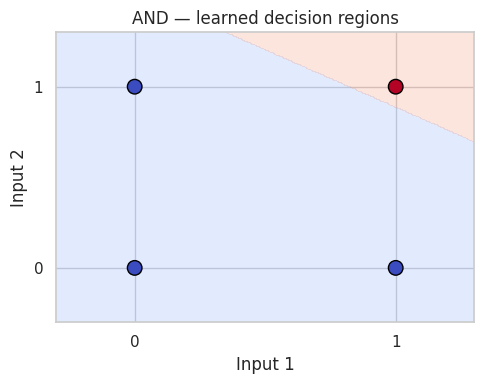

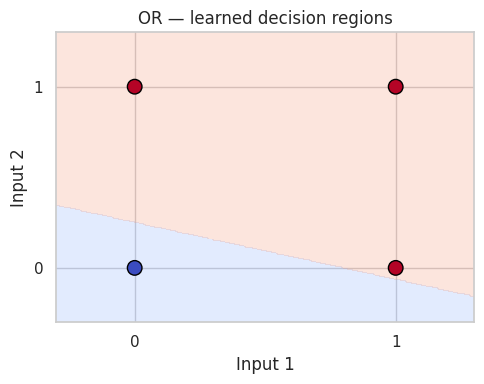

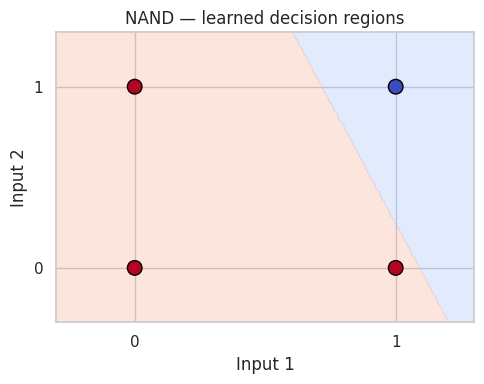

In [4]:
def plot_gate_boundary(model, gate_name, target):
    xx, yy = np.meshgrid(np.linspace(-0.3, 1.3, 250),
                         np.linspace(-0.3, 1.3, 250))
    grid = np.c_[xx.ravel(), yy.ravel()]
    zz = model.predict(grid).reshape(xx.shape)
    plt.figure(figsize=(5, 4))
    plt.contourf(xx, yy, zz, alpha=0.25, levels=[-0.5, 0.5, 1.5], cmap="coolwarm")
    plt.scatter(X_gate[:,0], X_gate[:,1], c=target, cmap="coolwarm",
                edgecolor="black", s=110)
    plt.xlabel("Input 1")
    plt.ylabel("Input 2")
    plt.title(f"{gate_name} — learned decision regions")
    plt.xticks([0,1]); plt.yticks([0,1])
    plt.tight_layout()
    plt.show()

for gate in ["AND", "OR", "NAND"]:
    plot_gate_boundary(gate_models[gate], gate, truth_tables[gate])

## 5. Train XOR and observe weight updates
XOR is **not linearly separable**. A single straight decision boundary cannot classify all four XOR input patterns correctly. The perceptron learning algorithm therefore cannot reach zero errors for XOR, although it continues updating weights.

In [5]:
xor_model = SingleLayerPerceptron(learning_rate=0.1, epochs=20, random_state=7)
xor_model.fit(X_gate, truth_tables["XOR"])
xor_pred = xor_model.predict(X_gate)

print("XOR final weights:", np.round(xor_model.weights, 4))
print("XOR final bias:", round(float(xor_model.bias), 4))
print("Epochs run:", xor_model.epochs_run)
print("Converged:", xor_model.converged)
print("XOR accuracy:", f"{np.mean(xor_pred == truth_tables['XOR'])*100:.2f}%")
display(pd.DataFrame({
    "Input": [tuple(row) for row in X_gate],
    "Actual XOR": truth_tables["XOR"],
    "Predicted XOR": xor_pred,
    "Correct": xor_pred == truth_tables["XOR"]
}))

XOR final weights: [-0.0749  0.0972]
XOR final bias: 0.0
Epochs run: 20
Converged: False
XOR accuracy: 25.00%


,Input,Actual XOR,Predicted XOR,Correct
0,"(0, 0)",0,1,False
1,"(0, 1)",1,1,True
2,"(1, 0)",1,0,False
3,"(1, 1)",0,1,False


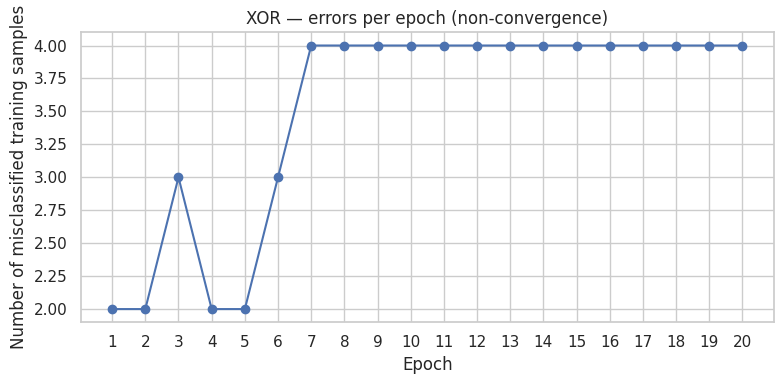

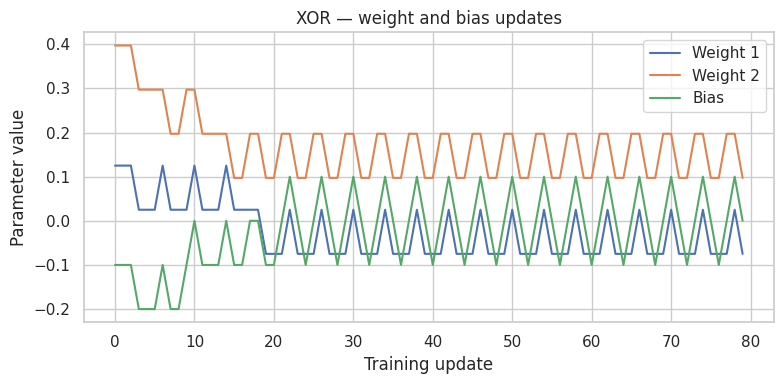

In [6]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(xor_model.errors_per_epoch)+1),
         xor_model.errors_per_epoch, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Number of misclassified training samples")
plt.title("XOR — errors per epoch (non-convergence)")
plt.xticks(range(1, len(xor_model.errors_per_epoch)+1))
plt.tight_layout()
plt.show()

# Plot the sequence of weight updates across individual training examples
history = np.array(xor_model.weight_history)
plt.figure(figsize=(8, 4))
plt.plot(history[:,0], label="Weight 1")
plt.plot(history[:,1], label="Weight 2")
plt.plot(xor_model.bias_history, label="Bias")
plt.xlabel("Training update")
plt.ylabel("Parameter value")
plt.title("XOR — weight and bias updates")
plt.legend()
plt.tight_layout()
plt.show()

## 6. Compare all four logic gates

In [7]:
all_gate_rows = []
for gate, target in truth_tables.items():
    if gate == "XOR":
        model = xor_model
    else:
        model = gate_models[gate]
    pred = model.predict(X_gate)
    all_gate_rows.append({
        "Logic Gate": gate,
        "Linearly separable": "No" if gate == "XOR" else "Yes",
        "Converged": model.converged,
        "Epochs": model.epochs_run,
        "Accuracy (%)": round(np.mean(pred == target)*100, 2),
        "SLP outcome": "Does not converge to perfect solution" if gate == "XOR"
                       else "Converges"
    })
logic_comparison = pd.DataFrame(all_gate_rows)
display(logic_comparison)

,Logic Gate,Linearly separable,Converged,Epochs,Accuracy (%),SLP outcome
0,AND,Yes,True,3,100.0,Converges
1,OR,Yes,True,2,100.0,Converges
2,NAND,Yes,True,12,100.0,Converges
3,XOR,No,False,20,25.0,Does not converge to perfect solution


## 7. Question 3 — Apply SLP to a dataset from the handout

### Dataset A: Scholarship eligibility
The page 3 sample image gives internal assessment, attendance percentage and scholarship eligibility (1 = Eligible, 0 = Not Eligible).

In [8]:
scholarship = pd.DataFrame({
    "Student": ["S1","S2","S3","S4","S5","S6","S7","S8"],
    "Internal Assessment": [85,75,65,45,50,30,90,40],
    "Attendance (%)": [90,85,80,60,55,45,95,50],
    "Scholarship Eligibility": [1,1,1,0,0,0,1,0]
})
display(scholarship)

,Student,Internal Assessment,Attendance (%),Scholarship Eligibility
0,S1,85,90,1
1,S2,75,85,1
2,S3,65,80,1
3,S4,45,60,0
4,S5,50,55,0
5,S6,30,45,0
6,S7,90,95,1
7,S8,40,50,0


In [9]:
# Scale input features so that the perceptron can learn with stable updates.
# Fit the scaler manually using training data only (all 8 rows are used here
# as a small classroom demonstration, not as a generalisation estimate).
scholarship_features = scholarship[["Internal Assessment", "Attendance (%)"]].to_numpy(dtype=float)
scholarship_target = scholarship["Scholarship Eligibility"].to_numpy(dtype=int)

sch_mean = scholarship_features.mean(axis=0)
sch_std = scholarship_features.std(axis=0)
sch_std[sch_std == 0] = 1
X_sch_scaled = (scholarship_features - sch_mean) / sch_std

sch_model = SingleLayerPerceptron(learning_rate=0.1, epochs=1000, random_state=11)
sch_model.fit(X_sch_scaled, scholarship_target)
sch_pred = sch_model.predict(X_sch_scaled)

print("Scholarship weights:", np.round(sch_model.weights, 4))
print("Scholarship bias:", round(float(sch_model.bias), 4))
print("Converged:", sch_model.converged, "| Epochs:", sch_model.epochs_run)
print("Training accuracy:", f"{np.mean(sch_pred == scholarship_target)*100:.2f}%")
display(scholarship.assign(Predicted=sch_pred,
                           Correct=(sch_pred == scholarship_target)))

Scholarship weights: [-0.0319  0.2987]
Scholarship bias: -0.1
Converged: True | Epochs: 2
Training accuracy: 100.00%


,Student,Internal Assessment,Attendance (%),Scholarship Eligibility,Predicted,Correct
0,S1,85,90,1,1,True
1,S2,75,85,1,1,True
2,S3,65,80,1,1,True
3,S4,45,60,0,0,True
4,S5,50,55,0,0,True
5,S6,30,45,0,0,True
6,S7,90,95,1,1,True
7,S8,40,50,0,0,True


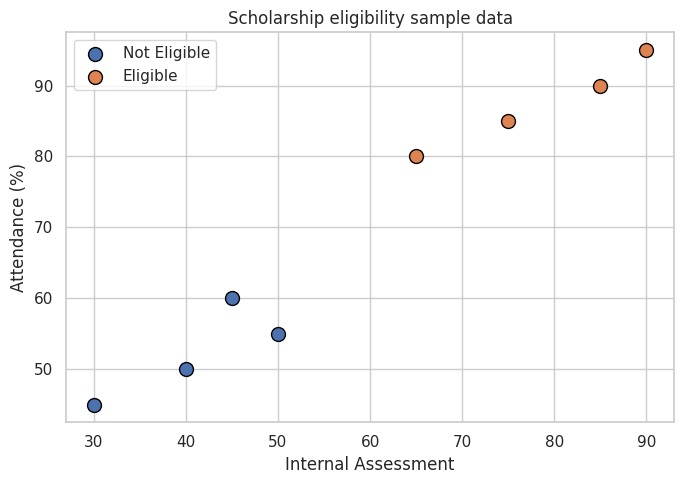

In [10]:
plt.figure(figsize=(7, 5))
for label, name, color in [(0, "Not Eligible", "tab:red"), (1, "Eligible", "tab:blue")]:
    mask = scholarship_target == label
    plt.scatter(scholarship_features[mask,0], scholarship_features[mask,1],
                label=name, s=100, edgecolor="black")
plt.xlabel("Internal Assessment")
plt.ylabel("Attendance (%)")
plt.title("Scholarship eligibility sample data")
plt.legend()
plt.tight_layout()
plt.show()

### Dataset B: Candidate selection
The page 3 sample image gives binary technical test and interview outcomes, with selection as the target.

In [11]:
candidates = pd.DataFrame({
    "Candidate": ["C1","C2","C3","C4","C5","C6","C7","C8"],
    "Technical Test": [1,1,0,0,1,0,1,0],
    "Interview": [1,0,1,0,1,0,0,1],
    "Selection": [1,1,1,0,1,0,1,1]
})
display(candidates)

,Candidate,Technical Test,Interview,Selection
0,C1,1,1,1
1,C2,1,0,1
2,C3,0,1,1
3,C4,0,0,0
4,C5,1,1,1
5,C6,0,0,0
6,C7,1,0,1
7,C8,0,1,1


### 7A. Data quality checks and preprocessing
Inspect missing values, duplicates and numeric feature types before fitting the sample-dataset perceptrons.

In [ ]:
print('Scholarship missing values:', scholarship.isna().sum().sum())
print('Scholarship duplicate rows:', scholarship.duplicated().sum())
print('Candidate missing values:', candidates.isna().sum().sum())
print('Candidate duplicate rows:', candidates.duplicated().sum())
assert set(scholarship['Scholarship Eligibility'].unique()).issubset({0, 1})
assert set(candidates['Selection'].unique()).issubset({0, 1})
# Demonstrate robust imputation/scaling without overwriting the original handout values.
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
scholarship_preprocessed = StandardScaler().fit_transform(SimpleImputer(strategy='median').fit_transform(scholarship[['Internal Assessment', 'Attendance (%)']]))
candidate_preprocessed = StandardScaler().fit_transform(SimpleImputer(strategy='most_frequent').fit_transform(candidates[['Technical Test', 'Interview']]))
print('Preprocessed scholarship shape:', scholarship_preprocessed.shape)
print('Preprocessed candidate shape:', candidate_preprocessed.shape)


In [12]:
X_candidate = candidates[["Technical Test", "Interview"]].to_numpy(dtype=float)
y_candidate = candidates["Selection"].to_numpy(dtype=int)

candidate_model = SingleLayerPerceptron(learning_rate=0.1, epochs=100,
                                        random_state=13)
candidate_model.fit(X_candidate, y_candidate)
candidate_pred = candidate_model.predict(X_candidate)

print("Candidate weights:", np.round(candidate_model.weights, 4))
print("Candidate bias:", round(float(candidate_model.bias), 4))
print("Converged:", candidate_model.converged, "| Epochs:", candidate_model.epochs_run)
print("Training accuracy:", f"{np.mean(candidate_pred == y_candidate)*100:.2f}%")
display(candidates.assign(Predicted=candidate_pred,
                          Correct=(candidate_pred == y_candidate)))

Candidate weights: [0.3648 0.3553]
Candidate bias: -0.1
Converged: True | Epochs: 2
Training accuracy: 100.00%


,Candidate,Technical Test,Interview,Selection,Predicted,Correct
0,C1,1,1,1,1,True
1,C2,1,0,1,1,True
2,C3,0,1,1,1,True
3,C4,0,0,0,0,True
4,C5,1,1,1,1,True
5,C6,0,0,0,0,True
6,C7,1,0,1,1,True
7,C8,0,1,1,1,True


## Additional visualisations — training dynamics and dataset insights

In [ ]:

# 1. Compare errors per epoch for the three linearly separable gates
plt.figure(figsize=(8, 4))
for gate in ["AND", "OR", "NAND"]:
    errors = gate_models[gate].errors_per_epoch
    plt.plot(range(1, len(errors)+1), errors, marker="o", label=gate)
plt.xlabel("Epoch")
plt.ylabel("Misclassified samples")
plt.title("Training convergence — AND, OR and NAND")
plt.legend()
plt.tight_layout()
plt.show()

# 2. Plot the learned decision boundary for XOR (illustrates unavoidable errors)
xx, yy = np.meshgrid(np.linspace(-0.3, 1.3, 250),
                     np.linspace(-0.3, 1.3, 250))
grid = np.c_[xx.ravel(), yy.ravel()]
zz = xor_model.predict(grid).reshape(xx.shape)
plt.figure(figsize=(6, 5))
plt.contourf(xx, yy, zz, alpha=0.25, levels=[-0.5, 0.5, 1.5], cmap="coolwarm")
plt.scatter(X_gate[:,0], X_gate[:,1], c=truth_tables["XOR"],
            cmap="coolwarm", edgecolor="black", s=150)
for i, (a,b) in enumerate(X_gate):
    plt.annotate(f"({a},{b}) -> {truth_tables['XOR'][i]}",
                 (a,b), xytext=(7,7), textcoords="offset points")
plt.xlabel("Input 1")
plt.ylabel("Input 2")
plt.title("XOR — one linear boundary cannot separate both classes")
plt.xticks([0,1]); plt.yticks([0,1])
plt.tight_layout()
plt.show()

# 3. Scholarship dataset: scatter plot with learned boundary in original feature units
xx, yy = np.meshgrid(
    np.linspace(scholarship_features[:,0].min()-5, scholarship_features[:,0].max()+5, 250),
    np.linspace(scholarship_features[:,1].min()-5, scholarship_features[:,1].max()+5, 250)
)
grid_original = np.c_[xx.ravel(), yy.ravel()]
grid_scaled = (grid_original - sch_mean) / sch_std
regions = sch_model.predict(grid_scaled).reshape(xx.shape)
plt.figure(figsize=(7, 5))
plt.contourf(xx, yy, regions, alpha=0.18, levels=[-0.5,0.5,1.5], cmap="coolwarm")
for label, name in [(0,"Not Eligible"),(1,"Eligible")]:
    mask = scholarship_target == label
    plt.scatter(scholarship_features[mask,0], scholarship_features[mask,1],
                label=name, s=100, edgecolor="black")
plt.xlabel("Internal Assessment")
plt.ylabel("Attendance (%)")
plt.title("Scholarship eligibility — learned SLP decision regions")
plt.legend()
plt.tight_layout()
plt.show()

# 4. Candidate dataset: all four input combinations and observed selection labels
candidate_summary = candidates.groupby(["Technical Test","Interview"])["Selection"].agg(
    ["count","mean"]).reset_index()
display(candidate_summary)
plt.figure(figsize=(6, 5))
for label, name in [(0,"Not Selected"),(1,"Selected")]:
    mask = y_candidate == label
    plt.scatter(X_candidate[mask,0] + np.random.normal(0,0.025,mask.sum()),
                X_candidate[mask,1] + np.random.normal(0,0.025,mask.sum()),
                label=name, s=130, edgecolor="black")
plt.xticks([0,1]); plt.yticks([0,1])
plt.xlabel("Technical Test")
plt.ylabel("Interview")
plt.title("Candidate selection sample — observed classes")
plt.legend()
plt.tight_layout()
plt.show()

# 5. Training accuracy summary across logic gates and sample datasets
summary = pd.DataFrame({
    "Dataset": ["AND","OR","NAND","XOR","Scholarship","Candidate"],
    "Training accuracy (%)": [
        np.mean(gate_models["AND"].predict(X_gate)==truth_tables["AND"])*100,
        np.mean(gate_models["OR"].predict(X_gate)==truth_tables["OR"])*100,
        np.mean(gate_models["NAND"].predict(X_gate)==truth_tables["NAND"])*100,
        np.mean(xor_model.predict(X_gate)==truth_tables["XOR"])*100,
        np.mean(sch_pred==scholarship_target)*100,
        np.mean(candidate_pred==y_candidate)*100
    ]
})
display(summary)
plt.figure(figsize=(9, 4))
sns.barplot(data=summary, x="Dataset", y="Training accuracy (%)")
plt.ylim(0, 105)
plt.title("Training accuracy comparison")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


## 8. Analysis and discussion
- **Why do AND, OR and NAND converge?** Their positive and negative examples can be separated by a straight line in the two-dimensional input space.
- **Why does XOR fail?** Its positive examples (0,1) and (1,0) lie on opposite corners, while negative examples (0,0) and (1,1) occupy the other corners. No single linear boundary separates these classes.
- **What do weights do?** Weights control the contribution of each input to the net input.
- **What does bias do?** Bias shifts the decision boundary.
- **What is the learning rate?** It controls the size of each parameter update.
- **What is the activation function?** The binary step function converts the weighted sum plus bias into class 0 or 1.
- **Dataset interpretation:** The sample tables are tiny teaching datasets. Reported accuracy is training accuracy on those rows; it is not evidence of generalisation to unseen students/candidates.

## 9. Self-learning extensions — complete answers and implementation

The answers and code below extend the experiments already completed above. Run these cells after the perceptron class and sample datasets have been defined.


### 9.1 Compare learning rates 0.01 and 0.5

**Answer:** The learning rate controls the size of each weight and bias update. A smaller learning rate such as 0.01 usually makes smaller updates and may require more epochs. A larger learning rate such as 0.5 makes larger updates and may converge faster, but large updates can also cause unstable behaviour in some settings. For the classic perceptron update rule on a linearly separable dataset, convergence is guaranteed under the standard assumptions, but the number of updates depends on the data, initial weights and learning rate. Compare the actual epoch counts printed below rather than assuming one rate is always best.


In [ ]:
# Compare convergence for AND at two learning rates
learning_rate_results = []
for lr in [0.01, 0.5]:
    model_lr = SingleLayerPerceptron(learning_rate=lr, epochs=1000, random_state=42)
    model_lr.fit(X_gate, truth_tables["AND"])
    pred_lr = model_lr.predict(X_gate)
    learning_rate_results.append({
        "Learning rate": lr,
        "Epochs executed": len(model_lr.errors_per_epoch),
        "Final errors": model_lr.errors_per_epoch[-1],
        "Training accuracy (%)": (pred_lr == truth_tables["AND"]).mean() * 100,
        "Weights": model_lr.weights.copy(),
        "Bias": model_lr.bias
    })
    plt.plot(range(1, len(model_lr.errors_per_epoch)+1), model_lr.errors_per_epoch, label=f"lr={lr}")
plt.xlabel("Epoch")
plt.ylabel("Misclassified samples")
plt.title("AND gate convergence at different learning rates")
plt.legend()
plt.grid(alpha=.3)
plt.show()
display(pd.DataFrame(learning_rate_results))


### 9.2 Shuffle training examples at each epoch

**Answer:** Shuffling changes the order in which training examples update the weights. Since each update affects the next prediction, the final weights and bias can differ even when the model reaches the same truth table. Shuffling can reduce dependence on a fixed sample order. For a tiny deterministic truth table, different orders may still reach a valid solution; the exact parameters need not be identical.


In [ ]:
def fit_shuffled_perceptron(X, y, learning_rate=0.1, epochs=100, random_state=42):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=int)
    rng = np.random.default_rng(random_state)
    weights = rng.uniform(-0.5, 0.5, X.shape[1])
    bias = 0.0
    errors = []
    for epoch in range(epochs):
        mistakes = 0
        for idx in rng.permutation(len(X)):
            prediction = int(np.dot(X[idx], weights) + bias >= 0)
            update = learning_rate * (y[idx] - prediction)
            if update != 0:
                weights += update * X[idx]
                bias += update
                mistakes += 1
        errors.append(mistakes)
        if mistakes == 0:
            break
    return weights, bias, errors

for seed in [1, 7, 42]:
    w, b, err = fit_shuffled_perceptron(X_gate, truth_tables["AND"], random_state=seed)
    print(f"Seed={seed} | weights={np.round(w, 4)} | bias={b:.4f} | epochs={len(err)} | final errors={err[-1]}")


### 9.3 Train on a larger synthetic linearly separable dataset

**Answer:** A linearly separable synthetic dataset is generated below. The perceptron should learn a linear decision boundary and achieve high training accuracy when the classes are sufficiently separated. The plot displays the observations and the learned boundary. This experiment demonstrates that the SLP is not limited to Boolean truth tables; it can classify any dataset whose classes can be separated by a hyperplane.


In [ ]:
from sklearn.datasets import make_classification

X_synthetic, y_synthetic = make_classification(
    n_samples=200, n_features=2, n_informative=2, n_redundant=0,
    n_clusters_per_class=1, class_sep=2.0, flip_y=0,
    random_state=42
)
synthetic_model = SingleLayerPerceptron(learning_rate=0.1, epochs=1000, random_state=42)
synthetic_model.fit(X_synthetic, y_synthetic)
synthetic_pred = synthetic_model.predict(X_synthetic)
print("Synthetic dataset shape:", X_synthetic.shape)
print("Training accuracy:", round((synthetic_pred == y_synthetic).mean()*100, 2), "%")
print("Epochs:", len(synthetic_model.errors_per_epoch))

x_min, x_max = X_synthetic[:, 0].min()-0.5, X_synthetic[:, 0].max()+0.5
y_min, y_max = X_synthetic[:, 1].min()-0.5, X_synthetic[:, 1].max()+0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 250), np.linspace(y_min, y_max, 250))
grid = np.c_[xx.ravel(), yy.ravel()]
zz = synthetic_model.predict(grid).reshape(xx.shape)
plt.figure(figsize=(7, 5))
plt.contourf(xx, yy, zz, alpha=.2, cmap="coolwarm")
plt.scatter(X_synthetic[:, 0], X_synthetic[:, 1], c=y_synthetic, cmap="coolwarm", edgecolor="black", s=25)
plt.title("SLP on a larger synthetic linearly separable dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()


### 9.4 How does a Multi-Layer Perceptron learn XOR?

**Answer:** XOR is not linearly separable, so one perceptron cannot represent its decision boundary. An MLP adds one or more hidden layers with nonlinear activation functions. Hidden neurons learn intermediate combinations of the inputs; the output neuron combines those representations to produce XOR. The nonlinear activation is essential: stacking only linear layers is still equivalent to one linear transformation and cannot solve XOR. The following `MLPClassifier` experiment demonstrates this using one hidden layer.


In [ ]:
from sklearn.neural_network import MLPClassifier

mlp_xor = MLPClassifier(hidden_layer_sizes=(4,), activation="tanh", solver="lbfgs", max_iter=5000, random_state=42)
mlp_xor.fit(X_gate, truth_tables["XOR"])
mlp_xor_predictions = mlp_xor.predict(X_gate)
print("XOR truth table:", truth_tables["XOR"])
print("MLP predictions:", mlp_xor_predictions)
print("MLP training accuracy:", (mlp_xor_predictions == truth_tables["XOR"]).mean()*100, "%")


### 9.5 Replace the step activation with sigmoid

**Answer:** The sigmoid function is `σ(z) = 1 / (1 + exp(-z))`; it returns a smooth value between 0 and 1. Unlike the step function, it is differentiable, so its derivative can be used to calculate gradients. A standard sigmoid neuron is usually trained with gradient descent and backpropagation, not the basic perceptron mistake-correction rule. Backpropagation applies the chain rule to calculate how each weight contributed to the loss. A sigmoid output is a probability-like score; a threshold (commonly 0.5) converts it into a binary class. Merely replacing the activation while keeping the old update rule is not a complete sigmoid-learning algorithm.


In [ ]:
def sigmoid(z):
    z = np.clip(z, -500, 500)  # numerical stability
    return 1.0 / (1.0 + np.exp(-z))

def sigmoid_derivative_from_output(a):
    return a * (1.0 - a)

sample_net_inputs = np.array([-3.0, -1.0, 0.0, 1.0, 3.0])
sigmoid_outputs = sigmoid(sample_net_inputs)
sigmoid_demo = pd.DataFrame({
    "Net input z": sample_net_inputs,
    "Sigmoid output": sigmoid_outputs,
    "Derivative": sigmoid_derivative_from_output(sigmoid_outputs),
    "Predicted class at threshold 0.5": (sigmoid_outputs >= 0.5).astype(int)
})
display(sigmoid_demo)

plt.figure(figsize=(7, 4))
z_values = np.linspace(-8, 8, 300)
plt.plot(z_values, sigmoid(z_values), label="Sigmoid")
plt.axhline(0.5, linestyle="--", alpha=.6, label="0.5 threshold")
plt.xlabel("Net input z")
plt.ylabel("Activation output")
plt.title("Sigmoid activation function")
plt.legend()
plt.grid(alpha=.3)
plt.show()


## 11. Viva questions
1. Define a single-layer perceptron.
2. What is the role of weights and bias?
3. What is the perceptron learning rule?
4. What is the role of the learning rate?
5. What is a step activation function?
6. Define linear separability.
7. Which of AND, OR, NAND and XOR are linearly separable?
8. Why can an SLP not learn XOR perfectly?
9. What is the difference between an epoch and an update?
10. How can an MLP solve XOR?

## Conclusion
A single-layer perceptron learns linearly separable Boolean functions such as AND, OR and NAND. XOR is not linearly separable, so the SLP cannot converge to a perfect solution. The two sample datasets from the lab handout are also implemented and evaluated, with all predictions and training accuracies displayed.